# 🤖 Notebook 3 — Modelos Clásicos de ML

## ¿Qué son los modelos clásicos y por qué empezar con ellos?

Antes de usar BERT (que es pesado y complejo), siempre vale la pena probar modelos clásicos:

1. **Son rápidos** — se entrenan en segundos/minutos
2. **Son interpretables** — puedes ver qué palabras influyen más en la decisión
3. **Son una referencia (baseline)** — si BERT no supera al modelo clásico, algo está mal
4. **A veces son suficientes** — para texto corto y etiquetas claras, logistic regression puede lograr >95% F1

### Pipeline en este notebook:
```
Texto limpio → TF-IDF → [Logistic Regression | Random Forest | XGBoost | LightGBM]
                                                  ↓
                                    Evaluación + Comparación + Guardar mejor modelo
```

---

## 1. Importar Librerías

In [14]:
import sys
!{sys.executable} -m pip install xgboost lightgbm catboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 1.5 MB/s eta 0:01:07
   ---------------------------------------- 0.8/101.7 MB 1.7 MB/s eta 0:01:01
   ---------------------------------------- 1.0/101.7 MB 1.5 MB/s eta 0:01:06
    --------------------------------------- 1.3/101.7 MB 1.4 MB/s eta 0:01:11
    --------------------------------------- 1.6/101.7 MB 1.4 MB/s eta 0:01:15
    --------------------------------------- 1.8/101.7 MB 1.3 MB/s eta 0:01:17
    --------------------------------------- 1.8/101.7 MB 1.3 MB/s eta 0:01:17
    --------------------------------------- 2.1/101.7 MB 1.2 MB/s eta 0:01:20
    --------------------------------------- 2.4/101.7 MB 1.2 MB/s eta 0:01:20
   - -------------------------------------- 2.9/101.7 MB 1.3 MB/s eta 0:01:17
   - -------------------------------------- 3.1/101.7 MB 1.3 MB/s eta 0:01:16


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time
import warnings

# sklearn — librería de referencia para ML clásico en Python
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,    # precision, recall, f1 por clase
    confusion_matrix,          # tabla de verdaderos/falsos positivos
    roc_auc_score,             # área bajo la curva ROC
    roc_curve,                 # curva ROC para graficar
    f1_score,
    precision_recall_curve,    # curva precision-recall
)
from sklearn.pipeline import Pipeline  # encadena pasos de preprocessing + modelo

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

print('✅ Librerías sklearn cargadas')

# Intentar importar librerías opcionales de gradient boosting
try:
    from xgboost import XGBClassifier
    XGBOOST_OK = True
    print('✅ XGBoost disponible')
except ImportError:
    XGBOOST_OK = False
    print('⚠️  XGBoost no disponible — instala con: pip install xgboost')

try:
    from lightgbm import LGBMClassifier
    LGBM_OK = True
    print('✅ LightGBM disponible')
except ImportError:
    LGBM_OK = False
    print('⚠️  LightGBM no disponible — instala con: pip install lightgbm')

✅ Librerías sklearn cargadas
✅ XGBoost disponible
✅ LightGBM disponible


## 2. Cargar el Dataset Limpio

Usamos el dataset que generamos en el Notebook 2 (`phishing_clean.csv`).

In [2]:
DATA_PATH = '../data/processed/phishing_clean.csv'

# Cargamos solo 'texto' y 'label' — son las únicas columnas que usan los modelos
df = pd.read_csv(DATA_PATH, usecols=['texto', 'label'], low_memory=False)

# Asegurarnos de que no hay NaN y que label es entero
df = df.dropna(subset=['label', 'texto'])
df['label'] = df['label'].astype(int)
df['texto'] = df['texto'].fillna('').astype(str)

print(f'Dataset cargado: {len(df):,} registros')
print(f'HAM: {(df.label==0).sum():,} | PHISHING: {(df.label==1).sum():,}')

Dataset cargado: 131,338 registros
HAM: 63,949 | PHISHING: 67,389


## 3. TF-IDF — Convertir Texto a Números

### ¿Por qué necesitamos convertir texto a números?
Los modelos de ML matemáticos no entienden palabras. Necesitan vectores numéricos.

### ¿Qué es TF-IDF?
**TF** (Term Frequency): ¿Con qué frecuencia aparece esta palabra en *este* documento?
**IDF** (Inverse Document Frequency): ¿Esta palabra aparece en muchos documentos? Si aparece en todos, no es informativa (ej: 'the').

```
TF-IDF(palabra, documento) = TF × IDF
```

El resultado: cada email se convierte en un vector donde cada dimensión corresponde a una palabra del vocabulario, y el valor es el peso TF-IDF de esa palabra en ese email.

### Parámetros importantes de TfidfVectorizer:
| Parámetro | Valor | Significado |
|---|---|---|
| `max_features` | 50,000 | Solo usar las 50k palabras más frecuentes del corpus |
| `ngram_range` | (1,2) | Unigramas ('free') y bigramas ('click here') |
| `sublinear_tf` | True | Aplica log(TF) — reduce el peso de palabras muy repetidas |
| `min_df` | 2 | Ignorar palabras que aparecen en menos de 2 documentos |
| `strip_accents` | 'unicode' | Normalizar acentos (café → cafe) |

In [3]:
# === SPLIT TRAIN/TEST ===
# SIEMPRE dividir ANTES de fit_transform para evitar data leakage
# Data leakage: si el vectorizador ve los datos de test durante entrenamiento,
# aprende estadísticas del test y el modelo parece mejor de lo que realmente es.
#
# stratify=y asegura que la proporción de clases sea la misma en train y test
X = df['texto'].values  # array de strings
y = df['label'].values  # array de 0s y 1s

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,         # 20% para test, 80% para entrenamiento
    random_state=42,        # semilla para reproducibilidad
    stratify=y              # mantener proporción de clases
)

print(f'Train: {len(X_train):,} | Test: {len(X_test):,}')
print(f'Train → HAM: {(y_train==0).sum():,} | PHISHING: {(y_train==1).sum():,}')
print(f'Test  → HAM: {(y_test==0).sum():,} | PHISHING: {(y_test==1).sum():,}')

Train: 105,070 | Test: 26,268
Train → HAM: 51,159 | PHISHING: 53,911
Test  → HAM: 12,790 | PHISHING: 13,478


In [4]:
print('Entrenando vectorizador TF-IDF...')
t0 = time.time()

vectorizer = TfidfVectorizer(
    max_features=50_000,    # vocabulario máximo de 50k términos
    ngram_range=(1, 2),     # unigramas Y bigramas
    sublinear_tf=True,      # aplicar log(1+TF) — reduce dominancia de palabras muy comunes
    min_df=2,               # ignorar términos que aparecen en < 2 documentos
    strip_accents='unicode',# normalizar acentos
)

# fit_transform en train:
# fit()      → aprende el vocabulario y calcula IDF del corpus de entrenamiento
# transform() → convierte cada email en vector TF-IDF
# Resultado: matriz sparse de shape (n_train, 50000)
X_train_tfidf = vectorizer.fit_transform(X_train)

# transform en test:
# SOLO transform() — usa el vocabulario ya aprendido del train
# No reajustamos el vectorizador con datos de test
X_test_tfidf = vectorizer.transform(X_test)

print(f'Tiempo: {time.time()-t0:.1f}s')
print(f'Vocabulario: {len(vectorizer.vocabulary_):,} términos')
print(f'Matriz train: {X_train_tfidf.shape} — {X_train_tfidf.nnz:,} valores no-cero')
print(f'Densidad   : {X_train_tfidf.nnz / (X_train_tfidf.shape[0]*X_train_tfidf.shape[1]) * 100:.3f}%')
# La baja densidad es NORMAL — cada email usa solo una fracción del vocabulario total

# Guardar el vectorizador para usarlo en inferencia futura
os.makedirs('../models/artifacts', exist_ok=True)
joblib.dump(vectorizer, '../models/artifacts/tfidf_vectorizer.joblib')
print('✅ Vectorizador guardado en models/artifacts/tfidf_vectorizer.joblib')

Entrenando vectorizador TF-IDF...
Tiempo: 36.9s
Vocabulario: 50,000 términos
Matriz train: (105070, 50000) — 19,978,022 valores no-cero
Densidad   : 0.380%
✅ Vectorizador guardado en models/artifacts/tfidf_vectorizer.joblib


## 4. Función de Evaluación

Definimos una función reutilizable para evaluar cualquier modelo. La evaluaremos con:

- **Accuracy**: % de predicciones correctas — engañoso con clases desbalanceadas
- **Precision**: De todos los que marqué como phishing, ¿cuántos lo eran realmente? (Evita falsos positivos)
- **Recall**: De todos los phishings reales, ¿cuántos detecté? (Evita falsos negativos)
- **F1**: Media armónica de precision y recall — el más equilibrado
- **ROC-AUC**: Qué tan bien separa el modelo las dos clases — 0.5 = azar, 1.0 = perfecto

In [5]:
def evaluar_modelo(nombre, modelo, X_test, y_test, save_path=None):
    """
    Evalúa un modelo entrenado y muestra métricas completas.
    
    Parámetros:
        nombre    : nombre del modelo para mostrar en output
        modelo    : modelo ya entrenado con .predict() y .predict_proba()
        X_test    : features del conjunto de prueba
        y_test    : etiquetas reales del conjunto de prueba
        save_path : si se especifica, guarda la gráfica ROC aquí
    """
    # Predicciones de clase (0 o 1)
    y_pred = modelo.predict(X_test)
    
    # Probabilidades — necesarias para ROC-AUC
    # predict_proba devuelve [[P(0), P(1)], ...] — tomamos la columna 1 (P(phishing))
    y_prob = modelo.predict_proba(X_test)[:, 1]
    
    # Métricas
    roc = roc_auc_score(y_test, y_prob)
    f1  = f1_score(y_test, y_pred)
    
    print(f"\n{'='*55}")
    print(f"  MODELO: {nombre.upper()}")
    print(f"{'='*55}")
    
    # classification_report genera tabla con precision/recall/f1 por clase
    print(classification_report(y_test, y_pred, target_names=['HAM', 'PHISHING']))
    print(f"  ROC-AUC : {roc:.4f}")
    print(f"  F1 macro: {f1:.4f}")
    
    # Matriz de confusión: filas=real, columnas=predicho
    # TN FP
    # FN TP
    cm = confusion_matrix(y_test, y_pred)
    print(f"\n  Matriz de Confusión:")
    print(f"            Pred HAM  Pred PHISH")
    print(f"  Real HAM  {cm[0,0]:>8,}  {cm[0,1]:>10,}")
    print(f"  Real PHSH {cm[1,0]:>8,}  {cm[1,1]:>10,}")
    
    fp_rate = cm[0,1] / cm[0].sum() * 100  # Ham clasificado como phishing
    fn_rate = cm[1,0] / cm[1].sum() * 100  # Phishing clasificado como ham
    print(f"\n  Falsos positivos (ham→spam): {fp_rate:.2f}% (emails legítimos bloqueados)")
    print(f"  Falsos negativos (spam→ham): {fn_rate:.2f}% (phishing no detectado)")
    
    return {'modelo': nombre, 'roc_auc': roc, 'f1': f1,
            'fp_rate': fp_rate, 'fn_rate': fn_rate}


print('✅ Función de evaluación definida')

✅ Función de evaluación definida


## 5. Modelo 1: Regresión Logística

### ¿Por qué Logistic Regression es un excelente primer modelo?

- Funciona sorprendentemente bien con TF-IDF en clasificación de texto
- Rápido de entrenar (segundos para 100k emails)
- Interpretable: se puede ver el peso de cada palabra
- Sirve de **baseline** — cualquier modelo más complejo debe superarlo

### Parámetros:
- `C=1.0`: Regularización (inverso de lambda). Más bajo = más regularización = modelo más simple
- `solver='saga'`: Algoritmo de optimización — mejor para datasets grandes
- `n_jobs=-1`: Usar todos los núcleos del CPU

In [6]:
print('Entrenando Regresión Logística...')
t0 = time.time()

lr = LogisticRegression(
    C=1.0,              # regularización L2 por defecto
    max_iter=1000,      # máximo de iteraciones del optimizador
    solver='saga',      # eficiente para datasets grandes
    n_jobs=-1,          # paralelizar en todos los núcleos
    random_state=42,
)

lr.fit(X_train_tfidf, y_train)

print(f'Tiempo de entrenamiento: {time.time()-t0:.1f}s')

# Evaluar
metricas_lr = evaluar_modelo('Regresión Logística', lr, X_test_tfidf, y_test)

# Guardar el modelo
joblib.dump(lr, '../models/artifacts/logistic_regression.joblib')
print('\n✅ Modelo guardado')

Entrenando Regresión Logística...
Tiempo de entrenamiento: 2.8s

  MODELO: REGRESIÓN LOGÍSTICA
              precision    recall  f1-score   support

         HAM       0.99      0.98      0.99     12790
    PHISHING       0.98      0.99      0.99     13478

    accuracy                           0.99     26268
   macro avg       0.99      0.99      0.99     26268
weighted avg       0.99      0.99      0.99     26268

  ROC-AUC : 0.9989
  F1 macro: 0.9859

  Matriz de Confusión:
            Pred HAM  Pred PHISH
  Real HAM    12,567         223
  Real PHSH      159      13,319

  Falsos positivos (ham→spam): 1.74% (emails legítimos bloqueados)
  Falsos negativos (spam→ham): 1.18% (phishing no detectado)

✅ Modelo guardado


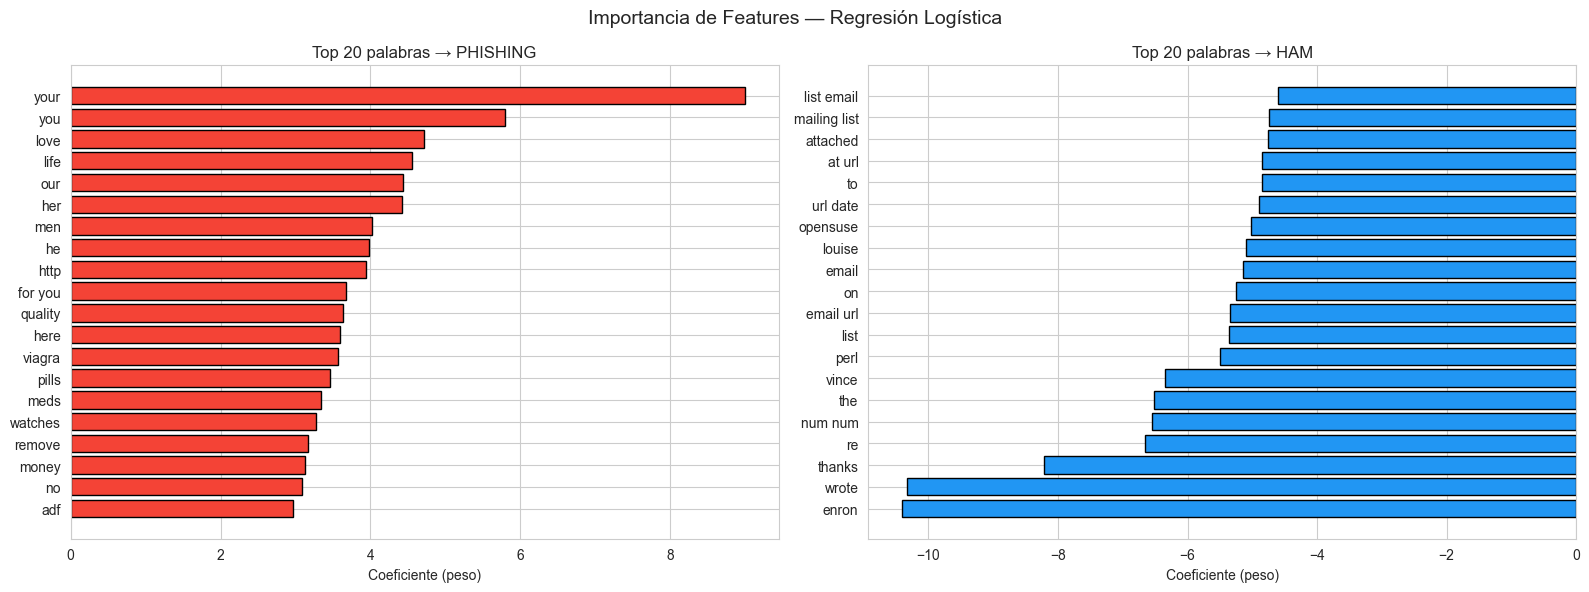

In [7]:
# === INTERPRETABILIDAD: Ver qué palabras pesan más ===
# En regresión logística, los coeficientes (pesos) indican la importancia de cada feature
# Coeficiente ALTO POSITIVO → esa palabra aumenta probabilidad de PHISHING
# Coeficiente ALTO NEGATIVO → esa palabra aumenta probabilidad de HAM

# Obtener nombres de features del vectorizador
feature_names = np.array(vectorizer.get_feature_names_out())

# Los coeficientes del modelo están en lr.coef_[0] (hay un vector por clase, tomamos el de clase 1)
coefs = lr.coef_[0]

# Índices de los N coeficientes más grandes (más positivos = más predictores de phishing)
TOP_N = 20
top_phishing_idx = np.argsort(coefs)[-TOP_N:][::-1]  # más positivos
top_ham_idx      = np.argsort(coefs)[:TOP_N]          # más negativos

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Palabras más predictoras de PHISHING
axes[0].barh(feature_names[top_phishing_idx][::-1],
             coefs[top_phishing_idx][::-1],
             color='#F44336', edgecolor='black')
axes[0].set_title(f'Top {TOP_N} palabras → PHISHING', fontsize=12)
axes[0].set_xlabel('Coeficiente (peso)')

# Palabras más predictoras de HAM
axes[1].barh(feature_names[top_ham_idx],
             coefs[top_ham_idx],
             color='#2196F3', edgecolor='black')
axes[1].set_title(f'Top {TOP_N} palabras → HAM', fontsize=12)
axes[1].set_xlabel('Coeficiente (peso)')

plt.suptitle('Importancia de Features — Regresión Logística', fontsize=14)
plt.tight_layout()
plt.savefig('../reports/figures/lr_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Modelo 2: Random Forest

### ¿Qué es Random Forest?
Un ensemble (conjunto) de muchos árboles de decisión. Cada árbol ve:
- Una muestra aleatoria de los datos (bootstrapping)
- Un subconjunto aleatorio de features

La predicción final es el **voto de mayoría** de todos los árboles.

**Ventajas:** Robusto, maneja bien features irrelevantes, poca probabilidad de overfitting
**Desventaja:** Más lento que LR para texto (50k features × 200 árboles)

In [8]:
print('Entrenando Random Forest (puede tardar 2-5 minutos)...')
t0 = time.time()

rf = RandomForestClassifier(
    n_estimators=200,   # 200 árboles — más árboles = más estable pero más lento
    max_depth=None,     # sin límite de profundidad — los árboles crecen hasta hojas puras
    min_samples_leaf=2, # cada hoja debe tener al menos 2 muestras — evita overfitting
    n_jobs=-1,          # paralelizar
    random_state=42,
)

rf.fit(X_train_tfidf, y_train)

print(f'Tiempo de entrenamiento: {time.time()-t0:.1f}s')

metricas_rf = evaluar_modelo('Random Forest', rf, X_test_tfidf, y_test)

joblib.dump(rf, '../models/artifacts/random_forest.joblib')
print('\n✅ Modelo guardado')

Entrenando Random Forest (puede tardar 2-5 minutos)...
Tiempo de entrenamiento: 30.5s

  MODELO: RANDOM FOREST
              precision    recall  f1-score   support

         HAM       0.98      0.98      0.98     12790
    PHISHING       0.98      0.98      0.98     13478

    accuracy                           0.98     26268
   macro avg       0.98      0.98      0.98     26268
weighted avg       0.98      0.98      0.98     26268

  ROC-AUC : 0.9980
  F1 macro: 0.9812

  Matriz de Confusión:
            Pred HAM  Pred PHISH
  Real HAM    12,521         269
  Real PHSH      239      13,239

  Falsos positivos (ham→spam): 2.10% (emails legítimos bloqueados)
  Falsos negativos (spam→ham): 1.77% (phishing no detectado)

✅ Modelo guardado


## 7. Modelo 3: XGBoost

### ¿Qué es Gradient Boosting?
A diferencia de Random Forest (árboles en paralelo), Gradient Boosting entrena árboles **en secuencia**: cada árbol intenta corregir los errores del anterior.

**XGBoost** es la implementación más eficiente y regularizada de este algoritmo.

**Parámetros clave:**
- `n_estimators`: Cuántos árboles secuenciales
- `learning_rate`: Qué tanto contribuye cada árbol nuevo (más bajo = más conservador)
- `max_depth`: Profundidad de cada árbol

In [9]:
if XGBOOST_OK:
    print('Entrenando XGBoost...')
    t0 = time.time()
    
    xgb = XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=6,
        eval_metric='logloss',  # métrica para monitorear durante entrenamiento
        n_jobs=-1,
        random_state=42,
        verbosity=0,            # silenciar output de XGBoost
    )
    
    xgb.fit(X_train_tfidf, y_train)
    
    print(f'Tiempo: {time.time()-t0:.1f}s')
    metricas_xgb = evaluar_modelo('XGBoost', xgb, X_test_tfidf, y_test)
    
    joblib.dump(xgb, '../models/artifacts/xgboost.joblib')
    print('✅ Modelo guardado')
else:
    print('XGBoost no disponible — omitiendo')
    metricas_xgb = None

Entrenando XGBoost...
Tiempo: 724.6s

  MODELO: XGBOOST
              precision    recall  f1-score   support

         HAM       0.99      0.97      0.98     12790
    PHISHING       0.97      0.99      0.98     13478

    accuracy                           0.98     26268
   macro avg       0.98      0.98      0.98     26268
weighted avg       0.98      0.98      0.98     26268

  ROC-AUC : 0.9981
  F1 macro: 0.9808

  Matriz de Confusión:
            Pred HAM  Pred PHISH
  Real HAM    12,421         369
  Real PHSH      152      13,326

  Falsos positivos (ham→spam): 2.89% (emails legítimos bloqueados)
  Falsos negativos (spam→ham): 1.13% (phishing no detectado)
✅ Modelo guardado


## 8. Modelo 4: LightGBM

### ¿Por qué LightGBM?
LightGBM es la alternativa de Microsoft a XGBoost. Sus ventajas principales:
- Mucho más rápido en datasets grandes (usa histogramas en lugar de valores exactos)
- Consume menos memoria
- Generalmente resultados similares o mejores que XGBoost

Para 100k+ registros con 50k features, LightGBM suele ser la opción óptima.

In [10]:
if LGBM_OK:
    print('Entrenando LightGBM...')
    t0 = time.time()
    
    lgbm = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,     # learning rate más bajo → más árboles necesarios pero mejor generalización
        num_leaves=63,          # controla la complejidad del árbol (2^max_depth - 1)
        min_child_samples=20,   # mínimo de muestras por hoja — regularización
        n_jobs=-1,
        random_state=42,
        verbose=-1,             # silenciar output de LightGBM
    )
    
    lgbm.fit(X_train_tfidf, y_train)
    
    print(f'Tiempo: {time.time()-t0:.1f}s')
    metricas_lgbm = evaluar_modelo('LightGBM', lgbm, X_test_tfidf, y_test)
    
    joblib.dump(lgbm, '../models/artifacts/lightgbm.joblib')
    print('✅ Modelo guardado')
else:
    print('LightGBM no disponible — omitiendo')
    metricas_lgbm = None

Entrenando LightGBM...
Tiempo: 477.0s

  MODELO: LIGHTGBM
              precision    recall  f1-score   support

         HAM       0.99      0.98      0.99     12790
    PHISHING       0.98      0.99      0.99     13478

    accuracy                           0.99     26268
   macro avg       0.99      0.99      0.99     26268
weighted avg       0.99      0.99      0.99     26268

  ROC-AUC : 0.9993
  F1 macro: 0.9881

  Matriz de Confusión:
            Pred HAM  Pred PHISH
  Real HAM    12,586         204
  Real PHSH      119      13,359

  Falsos positivos (ham→spam): 1.59% (emails legítimos bloqueados)
  Falsos negativos (spam→ham): 0.88% (phishing no detectado)
✅ Modelo guardado


## 9. Comparación Final de Modelos

Comparamos todos los modelos en una tabla y graficamos las curvas ROC para ver visualmente cuál separa mejor las clases.

In [11]:
# Recopilar métricas de todos los modelos
all_metricas = [metricas_lr, metricas_rf]
if metricas_xgb:  all_metricas.append(metricas_xgb)
if metricas_lgbm: all_metricas.append(metricas_lgbm)

results_df = pd.DataFrame(all_metricas).sort_values('roc_auc', ascending=False)
results_df = results_df.round(4)

print('=== TABLA COMPARATIVA ===')
print(results_df.to_string(index=False))

# Guardar resultados
os.makedirs('../reports', exist_ok=True)
results_df.to_csv('../reports/results_clasicos.csv', index=False)
print('\nResultados guardados en reports/results_clasicos.csv')

=== TABLA COMPARATIVA ===
             modelo  roc_auc     f1  fp_rate  fn_rate
           LightGBM   0.9993 0.9881   1.5950   0.8829
Regresión Logística   0.9989 0.9859   1.7435   1.1797
            XGBoost   0.9981 0.9808   2.8851   1.1278
      Random Forest   0.9980 0.9812   2.1032   1.7733

Resultados guardados en reports/results_clasicos.csv


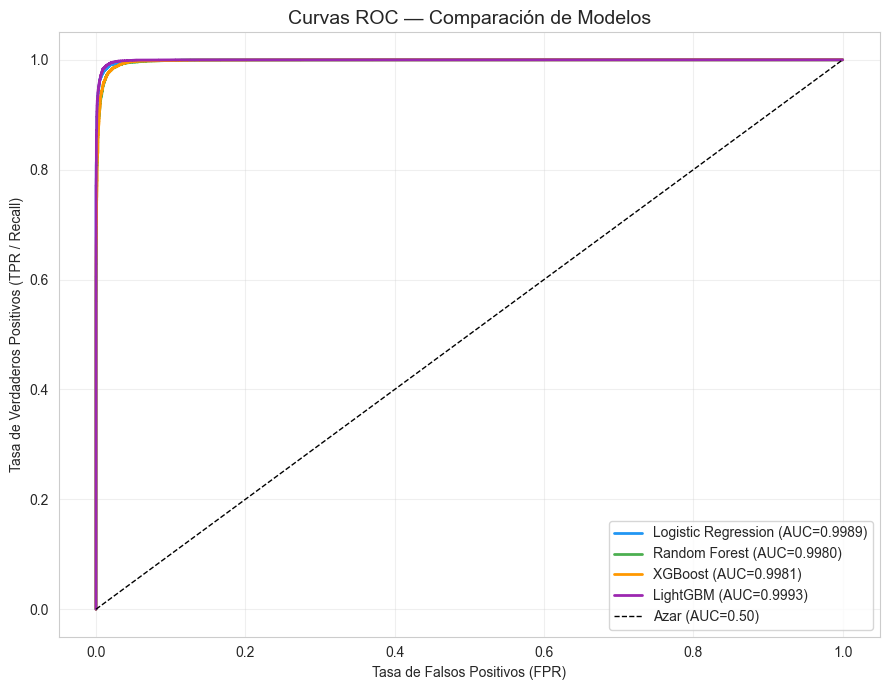

In [12]:
# === CURVAS ROC ===
# La curva ROC muestra el trade-off entre:
# - TPR (True Positive Rate / Recall): % de phishings detectados
# - FPR (False Positive Rate): % de hams clasificados como phishing
# 
# El punto ideal es arriba-izquierda (TPR=1, FPR=0)
# La línea diagonal representa un clasificador aleatorio (AUC=0.5)

fig, ax = plt.subplots(figsize=(9, 7))

# Diccionario de modelos entrenados
modelos = {'Logistic Regression': lr, 'Random Forest': rf}
if XGBOOST_OK: modelos['XGBoost'] = xgb
if LGBM_OK:   modelos['LightGBM'] = lgbm

colores = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

for (nombre, modelo), color in zip(modelos.items(), colores):
    y_prob = modelo.predict_proba(X_test_tfidf)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f'{nombre} (AUC={auc:.4f})', color=color, linewidth=2)

# Línea diagonal = clasificador aleatorio
ax.plot([0,1], [0,1], 'k--', linewidth=1, label='Azar (AUC=0.50)')

ax.set_title('Curvas ROC — Comparación de Modelos', fontsize=14)
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR / Recall)')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Guardar el Mejor Modelo

Identificamos el modelo con mayor ROC-AUC y lo marcamos como el modelo 'production'.

In [13]:
# Identificar el mejor modelo por ROC-AUC
best_row   = results_df.iloc[0]  # el primero después de sort_values(ascending=False)
best_name  = best_row['modelo']
best_auc   = best_row['roc_auc']

print(f'🏆 Mejor modelo: {best_name} (ROC-AUC: {best_auc:.4f})')

# Mapear nombre a objeto de modelo
name_to_model = {
    'Regresión Logística': lr,
    'Random Forest':       rf,
}
if XGBOOST_OK: name_to_model['XGBoost']   = xgb
if LGBM_OK:   name_to_model['LightGBM']  = lgbm

best_model = name_to_model.get(best_name, lr)  # fallback a LR

# Guardar como modelo 'best'
joblib.dump(best_model, '../models/artifacts/best_model_clasico.joblib')
joblib.dump(vectorizer, '../models/artifacts/tfidf_vectorizer.joblib')  # también el vectorizador

print('✅ Mejor modelo guardado en models/artifacts/best_model_clasico.joblib')
print('✅ Vectorizador guardado en models/artifacts/tfidf_vectorizer.joblib')

🏆 Mejor modelo: LightGBM (ROC-AUC: 0.9993)
✅ Mejor modelo guardado en models/artifacts/best_model_clasico.joblib
✅ Vectorizador guardado en models/artifacts/tfidf_vectorizer.joblib


## 11. Conclusiones y Siguiente Paso

### Lo que logramos:
- Establecimos un **baseline sólido** con modelos clásicos
- El mejor modelo clásico debería tener ROC-AUC > 0.97 (los datasets de phishing son relativamente fáciles para TF-IDF)
- Identificamos las palabras más predictoras de phishing

### ¿Para qué sirve BERT entonces?
BERT entiende el **contexto** de las palabras, no solo su frecuencia:
- TF-IDF ve 'bank account' como dos palabras separadas
- BERT entiende que juntas tienen un significado específico
- BERT detecta sutilezas como sarcasmo o phishing sofisticado que evita palabras obvias
- BERT generaliza mejor a phishing que *no existía* en el dataset de entrenamiento

---
*Siguiente paso → [04_bert_finetuning.ipynb](04_bert_finetuning.ipynb)*